In [154]:
! pip install seaborn

In [155]:
import pandas as pd


In [156]:
import numpy as np


In [157]:
import matplotlib.pyplot as plt

In [158]:
df = pd.read_csv('summer-travel-gps-full.csv')
df.head()

,lat,lon,date,city,country
0,51.481292,-0.451011,5/14/2014 9:07,West Drayton,United Kingdom
1,51.474005,-0.450999,5/14/2014 9:22,Hounslow,United Kingdom
2,51.478199,-0.446081,5/14/2014 10:51,Hounslow,United Kingdom
3,51.478199,-0.446081,5/14/2014 11:24,Hounslow,United Kingdom
4,51.474146,-0.451562,5/14/2014 11:38,Hounslow,United Kingdom


In [159]:
#Q1: how to get 2 columns from the dataframe (city and country)?

In [160]:
import pandas as pd

df = pd.read_csv("summer-travel-gps-full.csv")

df[["city", "country"]]

,city,country
0,West Drayton,United Kingdom
1,Hounslow,United Kingdom
2,Hounslow,United Kingdom
3,Hounslow,United Kingdom
4,Hounslow,United Kingdom
...,...,...
1754,Munich,Germany
1755,Munich,Germany
1756,Munich,Germany
1757,Munich,Germany


In [161]:
# Q2: how to get the first 5 rows of the "city" column?

In [162]:
df.head(5)

,lat,lon,date,city,country
0,51.481292,-0.451011,5/14/2014 9:07,West Drayton,United Kingdom
1,51.474005,-0.450999,5/14/2014 9:22,Hounslow,United Kingdom
2,51.478199,-0.446081,5/14/2014 10:51,Hounslow,United Kingdom
3,51.478199,-0.446081,5/14/2014 11:24,Hounslow,United Kingdom
4,51.474146,-0.451562,5/14/2014 11:38,Hounslow,United Kingdom


In [163]:
# Q3: how to use .loc to select the third row of the dataframe?

In [164]:
df.loc[2]

lat              51.478199
lon              -0.446081
date       5/14/2014 10:51
city              Hounslow
country     United Kingdom
Name: 2, dtype: object

In [165]:
# Q4: how to use .loc to select the first row in "country" column?

In [166]:
df.loc[1, 'country']

'United Kingdom'

In [167]:
# Q5: how to select the first 4 rows of ['city', 'date'] columns?

In [168]:
df.loc[5, ['city', 'date']]

city           Hounslow
date    5/14/2014 12:23
Name: 5, dtype: object

In [169]:
# Q6: how to get the value from the row in position 3 and the column in position 2

In [170]:
df.iloc [2, 1]

np.float64(-0.446081)

In [171]:
# Q7: how to use iloc to select every 300th row from a data set

In [172]:
df.iloc[::300]

,lat,lon,date,city,country
0,51.481292,-0.451011,5/14/2014 9:07,West Drayton,United Kingdom
300,41.377091,2.151175,5/20/2014 3:18,Barcelona,Spain
600,50.052338,19.946220,5/31/2014 21:10,Krakow,Poland
900,48.561181,9.059672,6/9/2014 15:12,Tübingen,Germany
1200,41.378301,2.187443,6/17/2014 16:37,Barcelona,Spain
1500,42.208201,20.735993,6/30/2014 8:27,Prizren,Kosovo


In [173]:
Part 2
How to select rows by some value(s)

SyntaxError: invalid syntax (1591503050.py, line 1)

In [ ]:

df = df = pd.read_csv('summer-travel-gps-full.csv')
df.tail()

In [ ]:
print(type(df))

In [ ]:
df = pd.read_csv("summer-travel-gps-full.csv")
is_munich = df["city"] == "Munich"
is_munich.head()   

In [ ]:
is_munich.sum()                  
is_munich.value_counts()         
df[is_munich].head()

In [ ]:
Q10: what cities were visited in spain that were not barcelona? Create a dataframe for it.

In [ ]:
spain_not_bcn = df[(df["country"] == "Spain") & (df["city"] != "Barcelona")]
spain_not_bcn.head()

In [ ]:
# Q11: select rows where either the city is munich, or the country is serbia

In [ ]:
munich_or_serbia = df[(df["country"] == "Serbia") | (df["city"] == "Munich")]
munich_or_serbia.head()

In [ ]:
# Q12: how many observations are west of the prime meridian?

In [ ]:
(df["lon"] < 0).sum()

In [ ]:
# Q13: get all rows that contain a city that starts with the letter G

In [ ]:
g_cities = df[df["city"].str.startswith("G")]
g_cities.head()

In [ ]:
# Q14: how many unique cities and countries in the dataset? 
# Also can you check missing values for the dataframe

In [ ]:
print(df["city"].nunique())
print(df["country"].nunique())

In [ ]:
df.isna().sum()  

In [ ]:
# Q15: group by country name and show the city names in each of the country.

In [ ]:
cities_by_country = (
    df.groupby("country")["city"]
    .unique()
    .reset_index()
)
cities_by_country

In [ ]:
Part 3

In [ ]:
# Q16: is the timestamp index unique? How can you use code to find it? 

In [ ]:
df = pd.read_csv("summer-travel-gps-full.csv", index_col='date', parse_dates=True)
df.head()

In [ ]:
# Q16: is the timestamp index unique? How can you use code to find it? 

In [ ]:
df.index.is_unique

In [ ]:
# Q17: drop duplicate index 

In [ ]:
df = df[~df.index.duplicated(keep="first")]
df.index.is_unique 

In [ ]:
df = df[~df.index.duplicated(keep="first")]

In [ ]:
print(df.head())

In [ ]:
# Q18: create a weekday and a weekend dataframe

In [ ]:
weekday = df[df.index.dayofweek < 5]     
weekend = df[df.index.dayofweek >= 5]

In [ ]:
print(len(weekday), len(weekend), len(df))  
weekday.head()
weekend.head()

In [ ]:
# Q19: calculate and plot the number of observations each day of the week has

date
Monday       263
Tuesday      254
Wednesday    254
Thursday     256
Friday       218
Saturday     269
Sunday       245
Name: count, dtype: int64


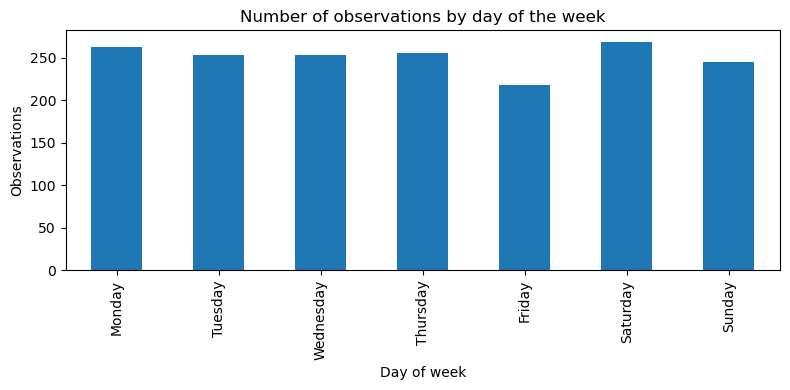

In [178]:
import matplotlib.pyplot as plt

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

counts = df.index.day_name().value_counts().reindex(order)
print(counts)

counts.plot(kind="bar", figsize=(8, 4))
plt.title("Number of observations by day of the week")
plt.xlabel("Day of week")
plt.ylabel("Observations")
plt.tight_layout()
plt.show()

In [ ]:
#Part 3

In [177]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.font_manager as fm

In [183]:
import os
print(os.getcwd())
print(os.path.exists('data/summer-travel-gps-full.csv'))
print(os.path.exists('data/summer-travel-gps-dbscan.csv'))

C:\Users\Madam Bayo
False
False


In [189]:
import os

home = r"C:\Users\Madam Bayo"
for root, dirs, files in os.walk(home):
    for f in files:
        if "summer-travel" in f:
            print(os.path.join(root, f))



C:\Users\Madam Bayo\summer-travel-gps-full.csv
C:\Users\Madam Bayo\.ipynb_checkpoints\summer-travel-gps-full-checkpoint.csv
C:\Users\Madam Bayo\AppData\Roaming\Microsoft\Excel\summer-travel-gps-full312912513098741278\summer-travel-gps-full((Autorecovered-312912513097490339)).xlsb
C:\Users\Madam Bayo\AppData\Roaming\Microsoft\Excel\summer-travel-gps-full312912513098741278\summer-travel-gps-full.csv.lnk
C:\Users\Madam Bayo\AppData\Roaming\Microsoft\Office\Recent\summer-travel-gps-full.LNK
C:\Users\Madam Bayo\AppData\Roaming\Microsoft\Windows\Recent\summer-travel-gps-full.lnk
C:\Users\Madam Bayo\Downloads\summer-travel-gps-full.csv
C:\Users\Madam Bayo\OneDrive\Desktop\summer-travel-gps-full.csv


In [192]:
df.head()

,lat,lon,city,country
date,,,,
2014-05-14 09:07:00,51.481292,-0.451011,West Drayton,United Kingdom
2014-05-14 09:22:00,51.474005,-0.450999,Hounslow,United Kingdom
2014-05-14 10:51:00,51.478199,-0.446081,Hounslow,United Kingdom
2014-05-14 11:24:00,51.478199,-0.446081,Hounslow,United Kingdom
2014-05-14 11:38:00,51.474146,-0.451562,Hounslow,United Kingdom


In [ ]:
First up: Bar Charts

In [ ]:
# Q1: Can you draw a bar chart for the most visited countries by using matplotlib and seaborn? You can use the df dataframe.
# Please style the chart to make it look nicer
# such as figsize, width, alpha, color, edgecolor, grid, xlim, and ylim

In [194]:
import matplotlib.pyplot as plt
import seaborn as sns

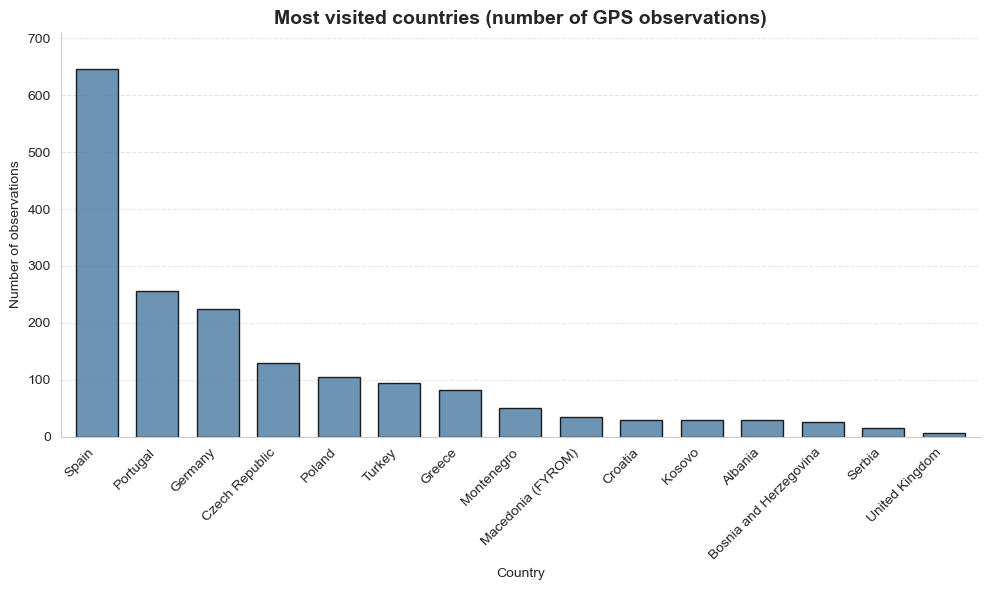

In [197]:
country_counts = df["country"].value_counts().reset_index()
country_counts.columns = ["country", "n_obs"]

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))                  # figsize

sns.barplot(
    data=country_counts, x="country", y="n_obs",
    width=0.7,                 # bar width
    color="steelblue",         # color
    alpha=0.85,                # transparency
    edgecolor="black",         # bar outline
    linewidth=1,
    ax=ax,
)
ax.set_title("Most visited countries (number of GPS observations)", fontsize=14, weight="bold")
ax.set_xlabel("Country")
ax.set_ylabel("Number of observations")

ax.grid(axis="y", linestyle="--", alpha=0.5)            
ax.set_axisbelow(True)                                   
ax.set_xlim(-0.6, len(country_counts) - 0.4)             
ax.set_ylim(0, country_counts["n_obs"].max() * 1.1)      

plt.xticks(rotation=45, ha="right")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Q2: Draw the same bar chart, but now for the most visited cities instead of countries

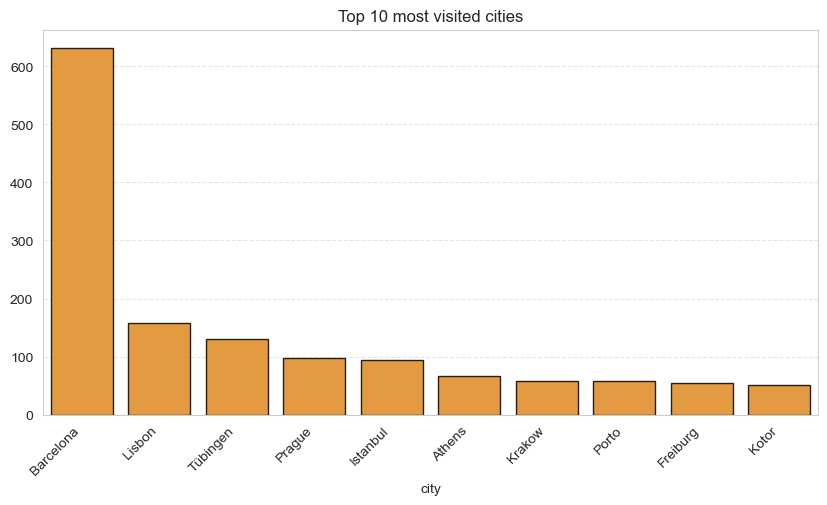

In [204]:
import seaborn as sns
import matplotlib.pyplot as plt

top = df["city"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top.index, y=top.values, color="darkorange", alpha=0.85, edgecolor="black")
plt.title("Top 10 most visited cities")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [ ]:
# Now you try: re-create the plot above, but make the bars orange with maroon edges.

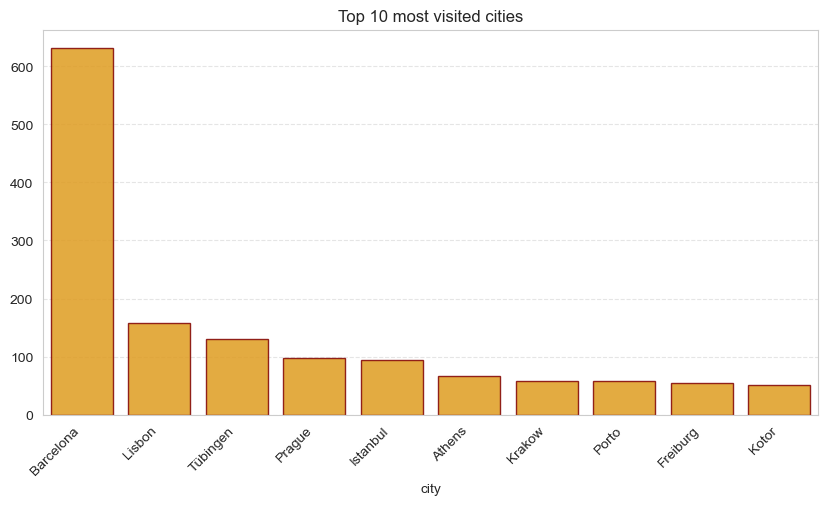

In [205]:
import seaborn as sns
import matplotlib.pyplot as plt

top = df["city"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top.index, y=top.values, color="orange", alpha=0.85, edgecolor="maroon")
plt.title("Top 10 most visited cities")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [ ]:
Next: scatter plots as simple maps

In [ ]:
# Q3: Draw a scatter plot the longitude and latitude data, with matplotlib and seaborn defaults. 
# You can use the rs dataframe.
# Please style the chart to make it look nicer with good size and alpha settings. 

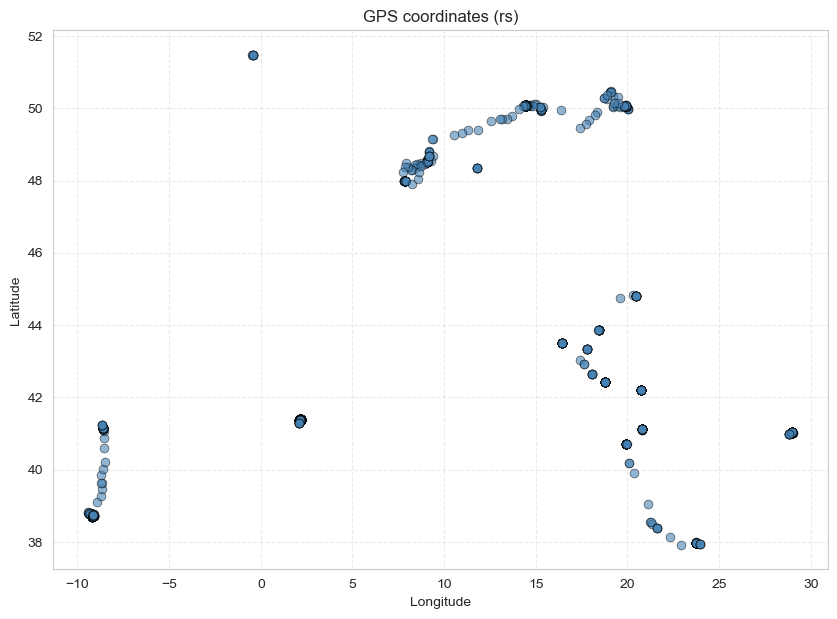

In [207]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x="lon", y="lat", s=40, alpha=0.6, color="steelblue", edgecolor="black")
plt.title("GPS coordinates (rs)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(linestyle="--", alpha=0.4)
plt.show()

In [ ]:
# get the count of records by date



In [208]:
countdata = df.groupby(df.index.date).size()
countdata.head()

2014-05-14    36
2014-05-15    61
2014-05-16    57
2014-05-17    64
2014-05-18    50
dtype: int64

In [ ]:
# Q4: Draw a  matplotlib and seaborn line chart from countdata. 
# Please style the chart to make it look nicer with good size and alpha settings. 

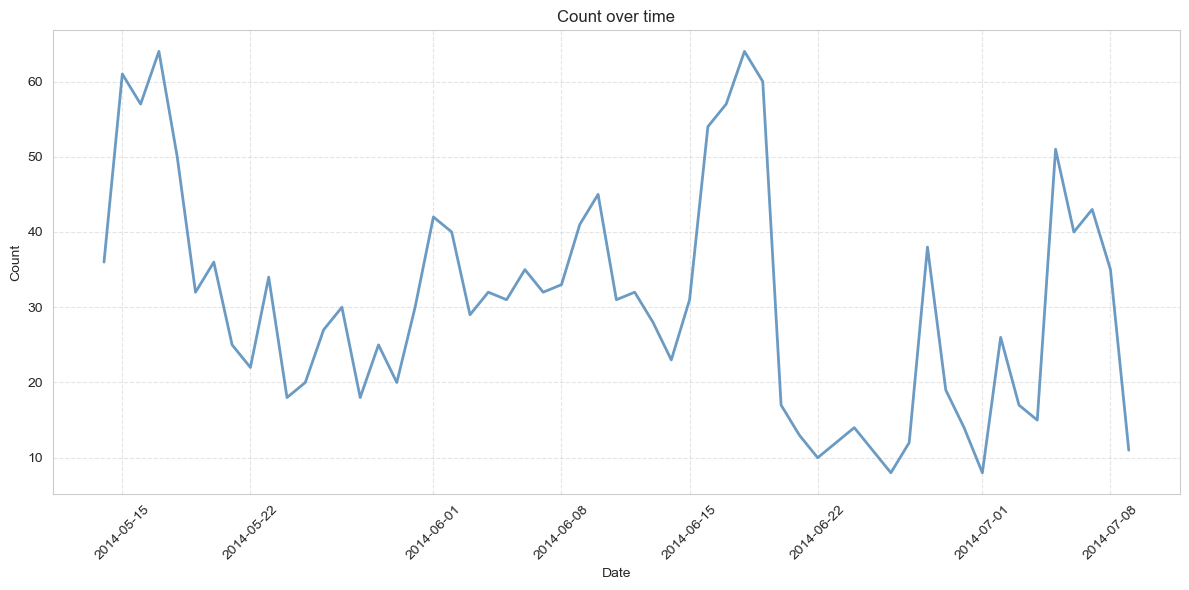

In [209]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.lineplot(x=countdata.index, y=countdata.values, color="steelblue", alpha=0.8, linewidth=2)
plt.title("Count over time")
plt.xlabel("Date")
plt.ylabel("Count")
plt.grid(linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Q5: Now you try: re-create the plot above with different line widths, colors, and point markers. 
# Play with moving the annotation labels around. Make the vertical tick marks 3 days apart instead of 5.
# experiment with a more advanced challenge like smoothing the line:
# - https://stackoverflow.com/questions/5283649/plot-smooth-line-with-pyplot
# - https://stackoverflow.com/questions/25825946/generating-smooth-line-graph-using-matplotlib

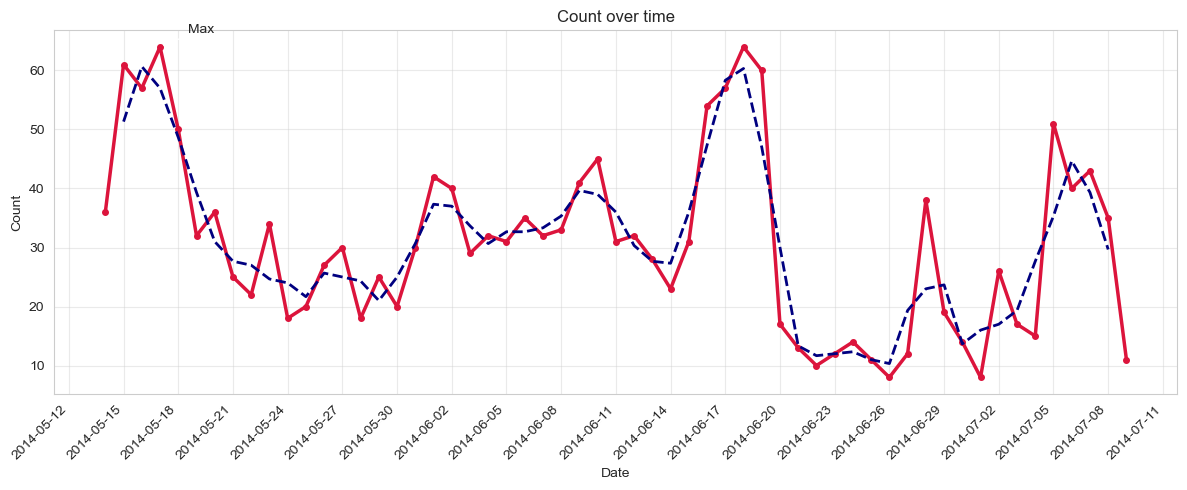

In [210]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(countdata.index, countdata.values, color="crimson", linewidth=2.5, marker="o", markersize=4)
ax.plot(countdata.index, countdata.rolling(3, center=True).mean(), color="navy", linestyle="--", linewidth=2)  # smoothed
ax.annotate("Max", xy=(countdata.idxmax(), countdata.max()), xytext=(20, 10), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))   # ticks every 3 days
plt.xticks(rotation=45, ha="right")
ax.set(title="Count over time", xlabel="Date", ylabel="Count")
ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# Pie Charts

In [211]:
cities = df['city'].value_counts()
print(cities.count())
cities.head()

113


city
Barcelona    632
Lisbon       158
Tübingen     131
Prague        97
Istanbul      94
Name: count, dtype: int64

In [ ]:
# Q6: draw a pie chart for cities.
# Please style the chart to make it look nicer. 

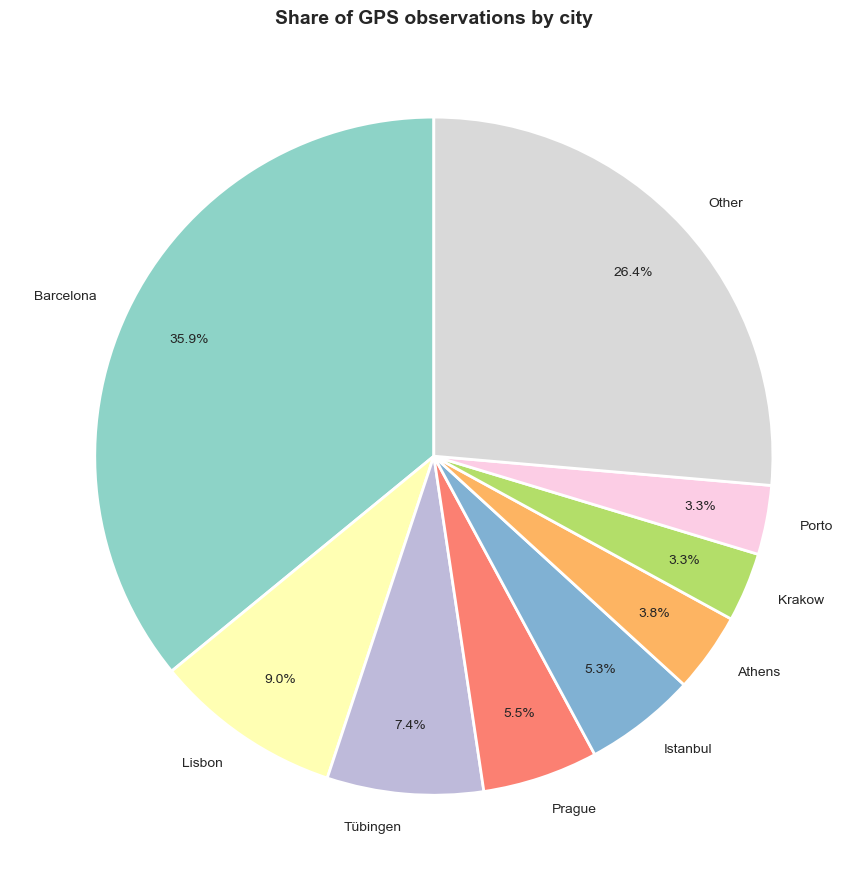

In [212]:
import matplotlib.pyplot as plt

counts = df["city"].value_counts()
top = counts.head(8)
top["Other"] = counts.iloc[8:].sum()          

plt.figure(figsize=(9, 9))
plt.pie(top, labels=top.index, autopct="%1.1f%%", startangle=90, pctdistance=0.8,
        colors=plt.cm.Set3.colors, wedgeprops={"edgecolor": "white", "linewidth": 2})
plt.title("Share of GPS observations by city", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

In [215]:
 !pip install keplergl

In [220]:
from keplergl import KeplerGl


In [221]:
!pip install keplergl

In [222]:
gps = df.reset_index()                          
gps["date"] = gps["date"].astype(str)           
m = KeplerGl(height=600)
m.add_data(data=gps[["date", "lat", "lon", "city", "country"]], name="Summer travel GPS")

In [224]:
from keplergl import KeplerGl

gps = df.reset_index()
gps["date"] = gps["date"].astype(str)

m = KeplerGl(height=600)
m.add_data(data=gps[["date", "lat", "lon", "city", "country"]], name="Summer travel GPS")
m

In [225]:
m.save_to_html(file_name="summer_travel_map.html")

import webbrowser, os
webbrowser.open("file://" + os.path.abspath("summer_travel_map.html"))

Map saved to summer_travel_map.html!


True